In [2]:
from requirements import *

# Extended Data Figure 2

In [3]:
adata_xenv1 = sc.read_h5ad(XEN_V1)

## ED Figure 2a. T/NK marker dotplot with lineage brackets

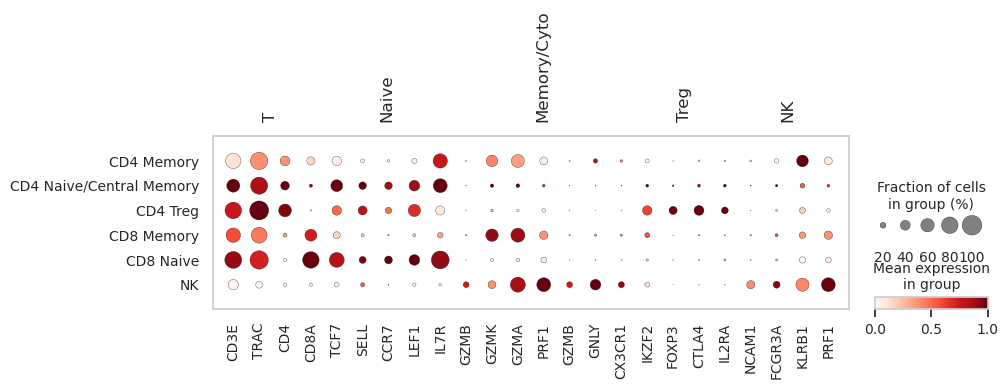

In [6]:
tcells = adata_xenv1[adata_xenv1.obs['ct_general'].isin(['NK','T Cell'])]
ct_dict = {
    'T': ['CD3E','TRAC','CD4','CD8A'],
    'Naive': ['TCF7','SELL','CCR7','LEF1','IL7R'],
    'Memory/Cyto': ['GZMB','GZMK','GZMA', 'PRF1','GZMB','GNLY','CX3CR1'],
    'Treg': ['IKZF2','FOXP3','CTLA4','IL2RA'],
    'NK': ['NCAM1','FCGR3A', 'KLRB1','PRF1']
}

ax = sc.pl.dotplot(tcells, ct_dict, groupby=['ct_refined'], dendrogram=False, 
                   mean_only_expressed = True, vmax = 1,
                   standard_scale = 'var', #categories_order = order,expression_cutoff = 0.3,
                   use_raw = False, var_group_labels=list(ct_dict.keys()),
                   figsize=(10,2.25))


## ED Figure 2e. Mean KIT expression in HSPCs, Control vs MDS-IB2 

In [13]:
tmp = adata_xenv1[adata_xenv1.obs['diagnosis'].isin(['MDS-IB2','Control-Lymph', 'Control-Donor'])]
tmp = tmp[tmp.obs['ct_general'] == 'HSPC']
tmp.obs['di\agnosis'] = [str(x) for x in tmp.obs['diagnosis']]
tmp.obs.loc[tmp.obs['diagnosis'].isin(['Control-Lymph', 'Control-Donor']), 'diagnosis'] = 'Control'

df = sc.get.obs_df(tmp, keys=['KIT','study_id',"diagnosis"])
counts = df['study_id'].value_counts()
keep = counts[counts > 10].index.tolist()
df = df[df['study_id'].isin(keep)]
kit_df = pd.DataFrame(df.groupby(['study_id'])['KIT'].mean())

di = dict(zip(adata_xenv1.obs['study_id'], adata_xenv1.obs['diagnosis']))
kit_df['diagnosis'] = [di[x] for x in kit_df.index]
kit_df

,KIT,diagnosis
study_id,,
C-1,0.474230,Control-Donor
C-2,NaN,Control-Donor
C-3,0.282170,Control-Donor
C-4,0.392813,Control-Donor
C-5,0.557781,Control-Donor
C-6,0.675985,Control-Lymph
C-7,0.412012,Control-Lymph
C-8,0.233557,Control-Lymph
C-9,0.085251,Control-Lymph


## ED Figure 2d. CD34 / KIT dotplot by cell type


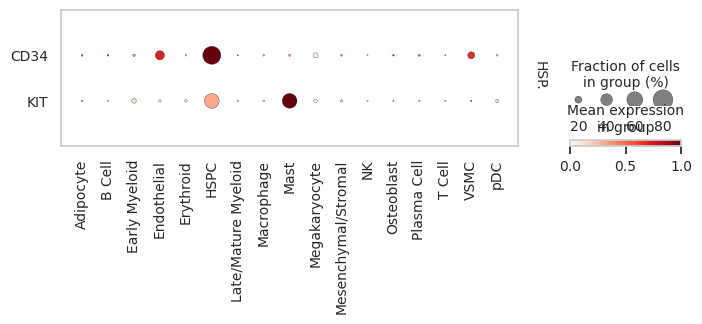

In [7]:
tcells = adata_xenv1[adata_xenv1.obs['ct_general'].isin(['NK','T Cell'])]
ct_dict = {
    'HSPC': ['CD34','KIT']
}

ax = sc.pl.dotplot(adata_xenv1, ct_dict, groupby=['ct_general'], dendrogram=False, swap_axes=True,
                   mean_only_expressed = True, vmax = 1,
                   standard_scale = 'var', 
                   use_raw = False, var_group_labels=list(ct_dict.keys()),
                   figsize=(8,1.25))
